--- First 5 Rows (head) ---
  animal_name  hair  feathers  eggs  milk  airborne  aquatic  predator  \
0    aardvark     1         0     0     1         0        0         1   
1    antelope     1         0     0     1         0        0         0   
2        bass     0         0     1     0         0        1         1   
3        bear     1         0     0     1         0        0         1   
4        boar     1         0     0     1         0        0         1   

   toothed  backbone  breathes  venomous  fins  legs  tail  domestic  catsize  \
0        1         1         1         0     0     4     0         0        1   
1        1         1         1         0     0     4     1         0        1   
2        1         1         0         0     1     0     1         0        0   
3        1         1         1         0     0     4     0         0        1   
4        1         1         1         0     0     4     1         0        1   

   class_type animal_type  
0           

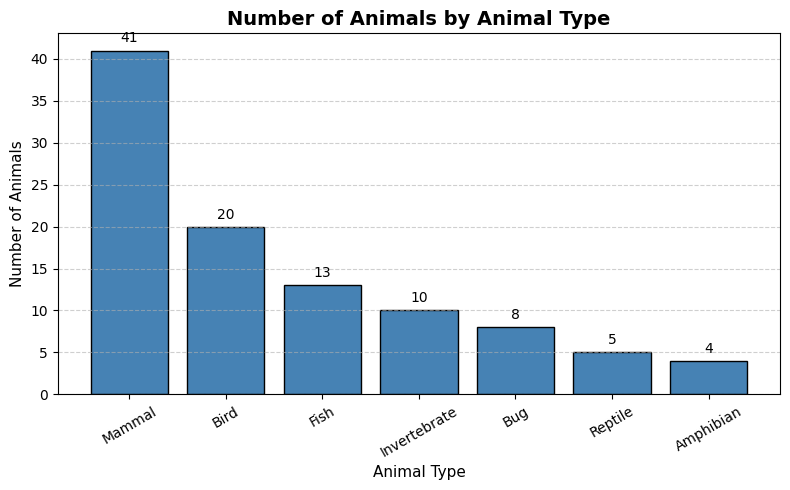

In [ ]:
# ==========================================
# Project: 03. Zoo Animals EDA
# Name: ROHIT SINGH
# Roll No: 2026B01010067
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. Load the Dataset
# ------------------------------------------
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/zoo/zoo.data"

columns = [
    "animal_name", "hair", "feathers", "eggs", "milk", "airborne",
    "aquatic", "predator", "toothed", "backbone", "breathes",
    "venomous", "fins", "legs", "tail", "domestic", "catsize", "class_type"
]

df = pd.read_csv(url, names=columns)

# Map numeric class_type (1-7) to readable animal type names
type_mapping = {
    1: "Mammal",
    2: "Bird",
    3: "Reptile",
    4: "Fish",
    5: "Amphibian",
    6: "Bug",
    7: "Invertebrate"
}
df["animal_type"] = df["class_type"].map(type_mapping)

# ------------------------------------------
# 2. Basic Dataset Exploration
# ------------------------------------------
print("--- First 5 Rows (head) ---")
print(df.head(), "\n")

print("--- Last 5 Rows (tail) ---")
print(df.tail(), "\n")

print(f"--- Dataset Shape ---\nRows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- Dataset Info ---")
df.info()
print("\n")

print("--- Statistical Summary (describe) ---")
print(df.describe(), "\n")

# ------------------------------------------
# Question 6: Check for Missing Values & Duplicates
# ------------------------------------------
print("--- Q6: Missing Values per Column ---")
print(df.isnull().sum())
print(f"Total missing values: {df.isnull().sum().sum()}\n")

exact_duplicates = df.duplicated().sum()
name_duplicates = df["animal_name"].duplicated().sum()
print(f"Exact duplicate rows: {exact_duplicates}")
print(f"Duplicate animal names: {name_duplicates}")
if name_duplicates > 0:
    print(df[df["animal_name"].duplicated(keep=False)][["animal_name", "animal_type", "venomous", "legs"]])
print("\n")

# ------------------------------------------
# Question 1: Animals Present in Each Animal Type
# ------------------------------------------
type_counts = df["animal_type"].value_counts()
print("--- Q1: Number of Animals per Animal Type ---")
print(type_counts, "\n")

# ------------------------------------------
# Question 2: Animals with Hair, Feathers, Eggs, or Milk
# ------------------------------------------
traits_q2 = ["hair", "feathers", "eggs", "milk"]
trait_counts_q2 = df[traits_q2].sum()

# Using a NumPy array for numeric calculations (counts & percentages)
counts_array = np.array(trait_counts_q2.values)
total_animals = len(df)
percentages_array = np.round((counts_array / total_animals) * 100, 2)

q2_summary = pd.DataFrame({
    "Characteristic": traits_q2,
    "Animal_Count": counts_array,
    "Percentage (%)": percentages_array
})
print("--- Q2: Count of Animals with Hair, Feathers, Eggs, or Milk ---")
print(q2_summary.to_string(index=False))

any_of_four = df[
    (df["hair"] == 1) | (df["feathers"] == 1) | (df["eggs"] == 1) | (df["milk"] == 1)
]
print(f"\nAnimals having AT LEAST ONE of (hair, feathers, eggs, milk): {len(any_of_four)} out of {total_animals}\n")

# ------------------------------------------
# Question 3: Animal Types with Largest Number of Records
# ------------------------------------------
sorted_types = type_counts.sort_values(ascending=False)
print("--- Q3: Animal Types with the Largest Number of Records ---")
print(sorted_types.head(3), "\n")

# ------------------------------------------
# Question 4: Animals that are Both Aquatic and Predator
# ------------------------------------------
aquatic_predators = df[(df["aquatic"] == 1) & (df["predator"] == 1)][
    ["animal_name", "animal_type", "fins", "legs"]
].sort_values(by="animal_name")

print(f"--- Q4: Aquatic & Predator Animals (Total: {len(aquatic_predators)}) ---")
print(aquatic_predators.to_string(index=False), "\n")

# ------------------------------------------
# Question 5: Most Common Characteristics in the Dataset
# ------------------------------------------
binary_features = [
    "hair", "feathers", "eggs", "milk", "airborne", "aquatic",
    "predator", "toothed", "backbone", "breathes", "venomous",
    "fins", "tail", "domestic", "catsize"
]

most_common_traits = df[binary_features].sum().sort_values(ascending=False)
print("--- Q5: Most Common Characteristics (Sorted Highest to Lowest) ---")
print(most_common_traits, "\n")

# ------------------------------------------
# Additional Required Analysis: groupby() & NumPy Stats
# ------------------------------------------
print("--- GroupBy Analysis: Average Legs & Key Traits by Animal Type ---")
grouped_stats = df.groupby("animal_type")[["legs", "predator", "aquatic", "airborne"]].mean().round(2)
print(grouped_stats.sort_values(by="legs", ascending=False), "\n")

# NumPy array statistics on the 'legs' column
legs_np = df["legs"].to_numpy()
print("--- NumPy Statistics on 'legs' ---")
print(f"Mean legs: {np.mean(legs_np):.2f}")
print(f"Median legs: {np.median(legs_np):.2f}")
print(f"Min legs: {np.min(legs_np)}, Max legs: {np.max(legs_np)}")
print(f"Std Deviation: {np.std(legs_np):.2f}\n")

# ------------------------------------------
# Chart 1: Bar Chart of Animal Types
# ------------------------------------------
plt.figure(figsize=(8, 5))
bars1 = plt.bar(type_counts.index, type_counts.values, color="steelblue", edgecolor="black")
plt.title("Number of Animals by Animal Type", fontsize=14, fontweight="bold")
plt.xlabel("Animal Type", fontsize=11)
plt.ylabel("Number of Animals", fontsize=11)
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.6, int(yval), ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

# ------------------------------------------
# Chart 2: Comparing Selected Characteristics
# ------------------------------------------
selected_chars = ["hair", "feathers", "eggs", "milk", "aquatic", "airborne"]
selected_counts = df[selected_chars].sum()

plt.figure(figsize=(8, 5))
bars2 = plt.bar(selected_counts.index, selected_counts.values, color="teal", edgecolor="black")
plt.title("Comparison of Selected Animal Characteristics", fontsize=14, fontweight="bold")
plt.xlabel("Characteristic", fontsize=11)
plt.ylabel("Number of Animals", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.8, int(yval), ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()